In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [113]:
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
    LabelEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import ExtraTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Importing Data

In [114]:
df = pd.read_csv("./telco.csv")

In [115]:
df.head(5)

,Customer ID,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents,Country,State,...,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Customer Status,Churn Label,Churn Score,CLTV,Churn Category,Churn Reason
0,8779-QRDMV,Male,78,No,Yes,No,No,0,United States,California,...,20,0.00,59.65,3,Churned,Yes,91,5433,Competitor,Competitor offered more data
1,7495-OOKFY,Female,74,No,Yes,Yes,Yes,1,United States,California,...,0,390.80,1024.10,3,Churned,Yes,69,5302,Competitor,Competitor made better offer
2,1658-BYGOY,Male,71,No,Yes,No,Yes,3,United States,California,...,0,203.94,1910.88,2,Churned,Yes,81,3179,Competitor,Competitor made better offer
3,4598-XLKNJ,Female,78,No,Yes,Yes,Yes,1,United States,California,...,0,494.00,2995.07,2,Churned,Yes,88,5337,Dissatisfaction,Limited range of services
4,4846-WHAFZ,Female,80,No,Yes,Yes,Yes,1,United States,California,...,0,234.21,3102.36,2,Churned,Yes,67,2793,Price,Extra data charges


# Data Exploration

In [116]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 50 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   object 
 1   Gender                             7043 non-null   object 
 2   Age                                7043 non-null   int64  
 3   Under 30                           7043 non-null   object 
 4   Senior Citizen                     7043 non-null   object 
 5   Married                            7043 non-null   object 
 6   Dependents                         7043 non-null   object 
 7   Number of Dependents               7043 non-null   int64  
 8   Country                            7043 non-null   object 
 9   State                              7043 non-null   object 
 10  City                               7043 non-null   object 
 11  Zip Code                           7043 non-null   int64

## Usefull Columns

<h3>Binomial</h3>
"Senior Citizen","Under 30","Dependents","Referred a Friend",
"Paperless Billing","Premium Tech Support","Unlimited Data",
"Multiple Lines","Online Backup","Device Protection Plan","Streaming TV",
"Streaming Movies","Streaming Music",
<h3>Numerical</h3>
"Tenure in Months","Avg Monthly GB Download","Monthly Charge",
<h3>Nominal</h3>
"Contract","Payment Method","Offer","Internet Type",
<h3>Ordinal</h3>
"Satisfaction Score"

In [117]:
cols = df.columns

In [118]:
useful_cols = ["Senior Citizen","Under 30","Dependents","Referred a Friend",
               "Paperless Billing","Premium Tech Support","Unlimited Data",
               "Multiple Lines","Online Backup","Device Protection Plan",
               "Streaming TV","Streaming Movies","Streaming Music",
               "Tenure in Months","Avg Monthly GB Download","Monthly Charge",
               "Contract","Payment Method","Offer","Internet Type",
               "Satisfaction Score","Churn Label"]

binomial_features = ["Senior Citizen","Under 30","Dependents","Referred a Friend",
            "Paperless Billing","Premium Tech Support","Unlimited Data",
            "Multiple Lines","Online Backup","Device Protection Plan",
            "Streaming TV","Streaming Movies","Streaming Music"]

numerical_features = ["Tenure in Months","Avg Monthly GB Download","Monthly Charge"]

nominal_features = ["Contract","Payment Method","Offer","Internet Type"]

ordinal_features = ["Satisfaction Score"]

In [119]:
not_useful_col = [x for x in cols if x not in useful_cols ]

In [120]:
df = df.drop(not_useful_col, axis=1)

In [121]:
df.shape

(7043, 22)

## Preprocessing

### Handling Missing Values

In [122]:
df['Offer'] = df['Offer'].fillna('No Offer')
df['Internet Type'] = df['Internet Type'].fillna('No Internet')

In [123]:
binary_transformer = OrdinalEncoder(dtype=int)
numeric_transformer = StandardScaler()
nominal_transformer = OneHotEncoder(handle_unknown="ignore")
ordinal_transformer = OrdinalEncoder()

In [124]:
# Combine them
preprocessor = ColumnTransformer(
    transformers=[
        ('binary', binary_transformer, binomial_features),
        ('num', numeric_transformer, numerical_features),
        ('nominal', nominal_transformer, nominal_features),
        ('ordinal', ordinal_transformer, ordinal_features)
    ],
    remainder='drop'
)

In [125]:
# # Define the full pipeline
# pipeline = Pipeline(steps=[
#     ('preprocessing', preprocessor),
#     ('classifier', DecisionTreeClassifier(random_state=42))
# ])

In [126]:
# Example
X = df.drop(columns=["Churn Label"])
y = df["Churn Label"]

# Encode target using LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [127]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "SVM (RBF)": SVC(kernel='rbf', probability=True, random_state=42),
    "KNN": KNeighborsClassifier()
}

In [128]:
results = {}

for name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    # 5-fold cross-validation on training data
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    results[name] = scores.mean()
    print(f"{name}: {scores.mean():.4f}")

Logistic Regression: 0.9546
Decision Tree: 0.9329
Random Forest: 0.9586
Gradient Boosting: 0.9594
AdaBoost: 0.9487
SVM (RBF): 0.9542
KNN: 0.9361


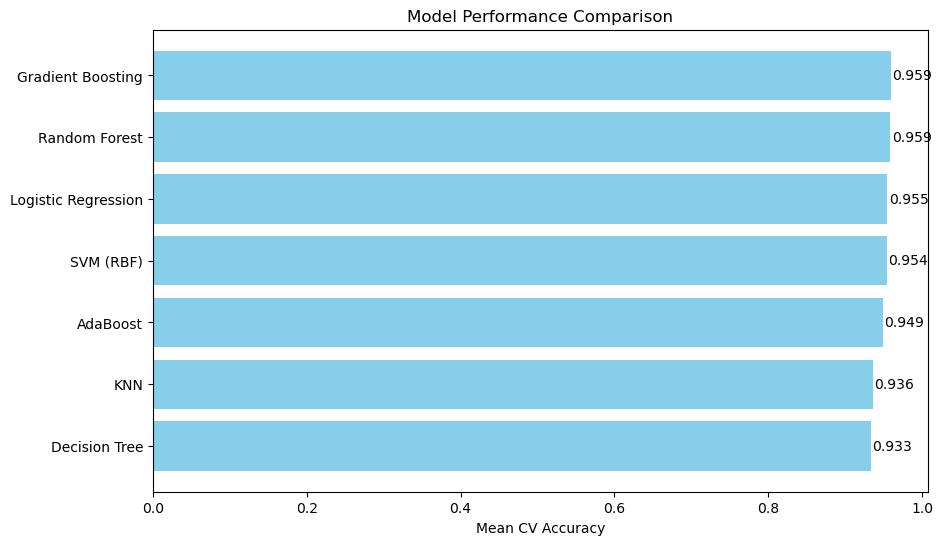

In [129]:
plt.figure(figsize=(10,6))
sorted_results = dict(sorted(results.items(), key=lambda x: x[1], reverse=True))
plt.barh(list(sorted_results.keys()), list(sorted_results.values()), color='skyblue')
plt.xlabel("Mean CV Accuracy")
plt.title("Model Performance Comparison")
plt.gca().invert_yaxis()  # Highest score on top
for i, (name, acc) in enumerate(sorted_results.items()):
    plt.text(acc + 0.002, i, f"{acc:.3f}", va='center')
plt.show()

In [130]:
max(results, key=results.get)

'Gradient Boosting'

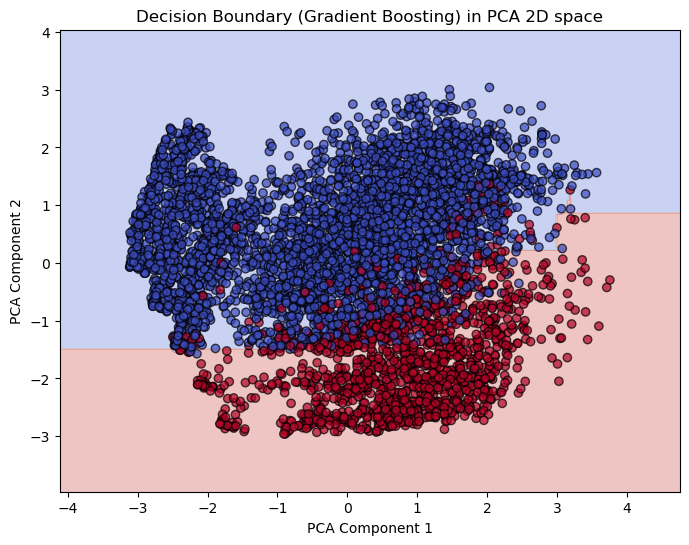

In [131]:
# -----------------------------
# Visualize decision boundary (2D projection)
# -----------------------------
from sklearn.decomposition import PCA
# Step 1: Transform features into numeric form via preprocessing
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

# Step 2: Reduce to 2D using PCA for visualization
pca = PCA(n_components=2)
X_train_2d = pca.fit_transform(X_train_transformed)
X_test_2d = pca.transform(X_test_transformed)

# Step 3: Refit model on 2D data
model_for_viz = models[best_model_name]
model_for_viz.fit(X_train_2d, y_train)

# Step 4: Plot decision boundary
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
Z = model_for_viz.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', alpha=0.7)
plt.title(f"Decision Boundary ({best_model_name}) in PCA 2D space")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

In [133]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=4,
    random_state=42
)

In [134]:
pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    # 5-fold cross-validation on training data
scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
results[name] = scores.mean()
print(f"{name}: {scores.mean():.4f}")

Decision Tree: 0.9560


In [137]:
pipe.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('binary', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [139]:
import joblib

# Suppose 'best_model' is your Gradient Boosting pipeline
joblib.dump(pipe, 'best_model_pipeline.pkl')


['best_model_pipeline.pkl']

72